In [1]:
import sys
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.model_selection import train_test_split
import seaborn as sns
import matplotlib.pyplot as plt
from preprocessing import CreditPreprocessor, add_features

In [2]:
BASE_DIR = Path.cwd().parent 
sys.path.append(str(BASE_DIR)) 
DATA_DIR = BASE_DIR / "data"
MODELS_DIR = BASE_DIR / "models"

DATA_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
DATA_DIR = BASE_DIR / "data"
raw_data = pd.read_csv(DATA_DIR / "train.csv")
df = raw_data.copy()
df.shape

(104805, 12)

In [4]:
df.head()

,Id,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
1,2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
2,3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
3,4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0
4,5,0,0.213179,74,0,0.375607,3500.0,3,0,1,0,1.0


In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104805 entries, 0 to 104804
Data columns (total 12 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   Id                                    104805 non-null  int64  
 1   SeriousDlqin2yrs                      104805 non-null  int64  
 2   RevolvingUtilizationOfUnsecuredLines  104805 non-null  float64
 3   age                                   104805 non-null  int64  
 4   NumberOfTime30-59DaysPastDueNotWorse  104805 non-null  int64  
 5   DebtRatio                             104805 non-null  float64
 6   MonthlyIncome                         84024 non-null   float64
 7   NumberOfOpenCreditLinesAndLoans       104805 non-null  int64  
 8   NumberOfTimes90DaysLate               104805 non-null  int64  
 9   NumberRealEstateLoansOrLines          104805 non-null  int64  
 10  NumberOfTime60-89DaysPastDueNotWorse  104805 non-null  int64  
 11  

In [7]:
df.isnull().sum()

Id                                          0
SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           20781
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       2749
dtype: int64

In [8]:
df = df.drop(columns=['Id'])

In [9]:
X = df.drop(columns=['SeriousDlqin2yrs'])
y = df['SeriousDlqin2yrs']

In [10]:
X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [11]:
X_train = pd.DataFrame(X_train_raw)
X_test = pd.DataFrame(X_test_raw)

print(X_train.shape)
print(X_test.shape)

(83844, 10)
(20961, 10)


In [12]:

preprocessor = CreditPreprocessor()
preprocessor.fit(X_train)

X_train_processed = preprocessor.clean_and_impute(X_train)
X_test_processed = preprocessor.clean_and_impute(X_test)

In [13]:
print("X_train")
print(X_train_processed.isnull().sum())
print("-"*40)
print("X_test")
print(X_test_processed.isnull().sum())

X_train
RevolvingUtilizationOfUnsecuredLines               0
age                                                0
NumberOfTime30-59DaysPastDueNotWorse               0
DebtRatio                                          0
MonthlyIncome                                      0
NumberOfOpenCreditLinesAndLoans                    0
NumberOfTimes90DaysLate                            0
NumberRealEstateLoansOrLines                       0
NumberOfTime60-89DaysPastDueNotWorse               0
NumberOfDependents                                 0
MonthlyIncomeMissing                               0
NumberOfDependentsMissing                          0
NumberOfTime30-59DaysPastDueNotWorseInvalidFlag    0
NumberOfTime60-89DaysPastDueNotWorseInvalidFlag    0
NumberOfTimes90DaysLateInvalidFlag                 0
dtype: int64
----------------------------------------
X_test
RevolvingUtilizationOfUnsecuredLines               0
age                                                0
NumberOfTime30-59DaysPastDueNo

In [14]:
print("X_train")
print(X_train_processed.duplicated().sum())
print("-"*40)
print("X_test")
print(X_test_processed.duplicated().sum())

X_train
264
----------------------------------------
X_test
15


In [15]:
print("X_train")
print(X_train_processed.shape)
print("-"*40)
print("X_test")
print(X_test_processed.shape)

X_train
(83844, 15)
----------------------------------------
X_test
(20961, 15)


In [16]:
print("Training target distribution")
print(y_train_raw.value_counts(normalize=True))
print("-"*40)

print("Testing target distribution")
print(y_test_raw.value_counts(normalize=True))


Training target distribution
SeriousDlqin2yrs
0    0.933686
1    0.066314
Name: proportion, dtype: float64
----------------------------------------
Testing target distribution
SeriousDlqin2yrs
0    0.933686
1    0.066314
Name: proportion, dtype: float64


In [17]:
print("X_train")
X_train_processed.describe(percentiles=[0.50, 0.75, 0.90, 0.95, 0.99, 0.999])


X_train


,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,MonthlyIncomeMissing,NumberOfDependentsMissing,NumberOfTime30-59DaysPastDueNotWorseInvalidFlag,NumberOfTime60-89DaysPastDueNotWorseInvalidFlag,NumberOfTimes90DaysLateInvalidFlag
count,83844.000000,83844.000000,83844.000000,83844.000000,8.384400e+04,83844.000000,83844.000000,83844.000000,83844.000000,83844.000000,83844.000000,83844.000000,83844.000000,83844.000000,83844.000000
mean,5.677536,52.359966,0.245587,349.971179,6.428416e+03,8.450420,0.089977,1.021826,0.064584,0.736821,0.198941,0.026191,0.001837,0.001837,0.001837
std,214.718071,14.760192,0.693676,1738.286501,1.413164e+04,5.120448,0.490882,1.140406,0.330122,1.102852,0.399206,0.159705,0.042818,0.042818,0.042818
min,0.000000,21.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.154517,52.000000,0.000000,0.367643,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.558632,63.000000,0.000000,0.869639,7.400000e+03,11.000000,0.000000,2.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
90%,0.980064,72.000000,1.000000,1290.700000,1.080000e+04,15.000000,0.000000,2.000000,0.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000
95%,1.000000,78.000000,2.000000,2460.000000,1.360000e+04,18.000000,1.000000,3.000000,0.000000,3.000000,1.000000,0.000000,0.000000,0.000000,0.000000
99%,1.091923,87.000000,3.000000,4984.570000,2.345248e+04,24.000000,2.000000,4.000000,2.000000,4.000000,1.000000,1.000000,0.000000,0.000000,0.000000
99.9%,1344.134000,93.000000,6.000000,10577.594000,7.292919e+04,34.000000,6.000000,9.000000,4.000000,6.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [18]:
print("X_test")
X_test_processed.describe(percentiles=[0.50, 0.75, 0.90, 0.95, 0.99, 0.999])

X_test


,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,MonthlyIncomeMissing,NumberOfDependentsMissing,NumberOfTime30-59DaysPastDueNotWorseInvalidFlag,NumberOfTime60-89DaysPastDueNotWorseInvalidFlag,NumberOfTimes90DaysLateInvalidFlag
count,20961.000000,20961.000000,20961.000000,20961.000000,2.096100e+04,20961.000000,20961.000000,20961.000000,20961.000000,20961.000000,20961.000000,20961.000000,20961.000000,20961.000000,20961.000000
mean,5.299926,52.318258,0.242641,374.412632,6.435179e+03,8.472592,0.084633,1.010448,0.064119,0.733887,0.195649,0.026382,0.001384,0.001384,0.001384
std,227.768952,14.784811,0.705618,3382.336325,1.359014e+04,5.158113,0.462210,1.122478,0.333257,1.109157,0.396709,0.160273,0.037171,0.037171,0.037171
min,0.000000,21.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.151408,52.000000,0.000000,0.362659,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.562838,63.000000,0.000000,0.859948,7.300000e+03,11.000000,0.000000,2.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
90%,0.983990,72.000000,1.000000,1215.000000,1.072800e+04,15.000000,0.000000,2.000000,0.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000
95%,1.000000,78.000000,2.000000,2452.000000,1.341600e+04,18.000000,1.000000,3.000000,0.000000,3.000000,1.000000,0.000000,0.000000,0.000000,0.000000
99%,1.075822,86.000000,3.000000,5084.000000,2.244820e+04,24.000000,2.000000,5.000000,2.000000,4.000000,1.000000,1.000000,0.000000,0.000000,0.000000
99.9%,958.800000,94.000000,6.000000,11536.440000,7.032000e+04,33.000000,6.000000,9.000000,4.000000,6.000000,1.000000,1.000000,1.000000,1.000000,1.000000


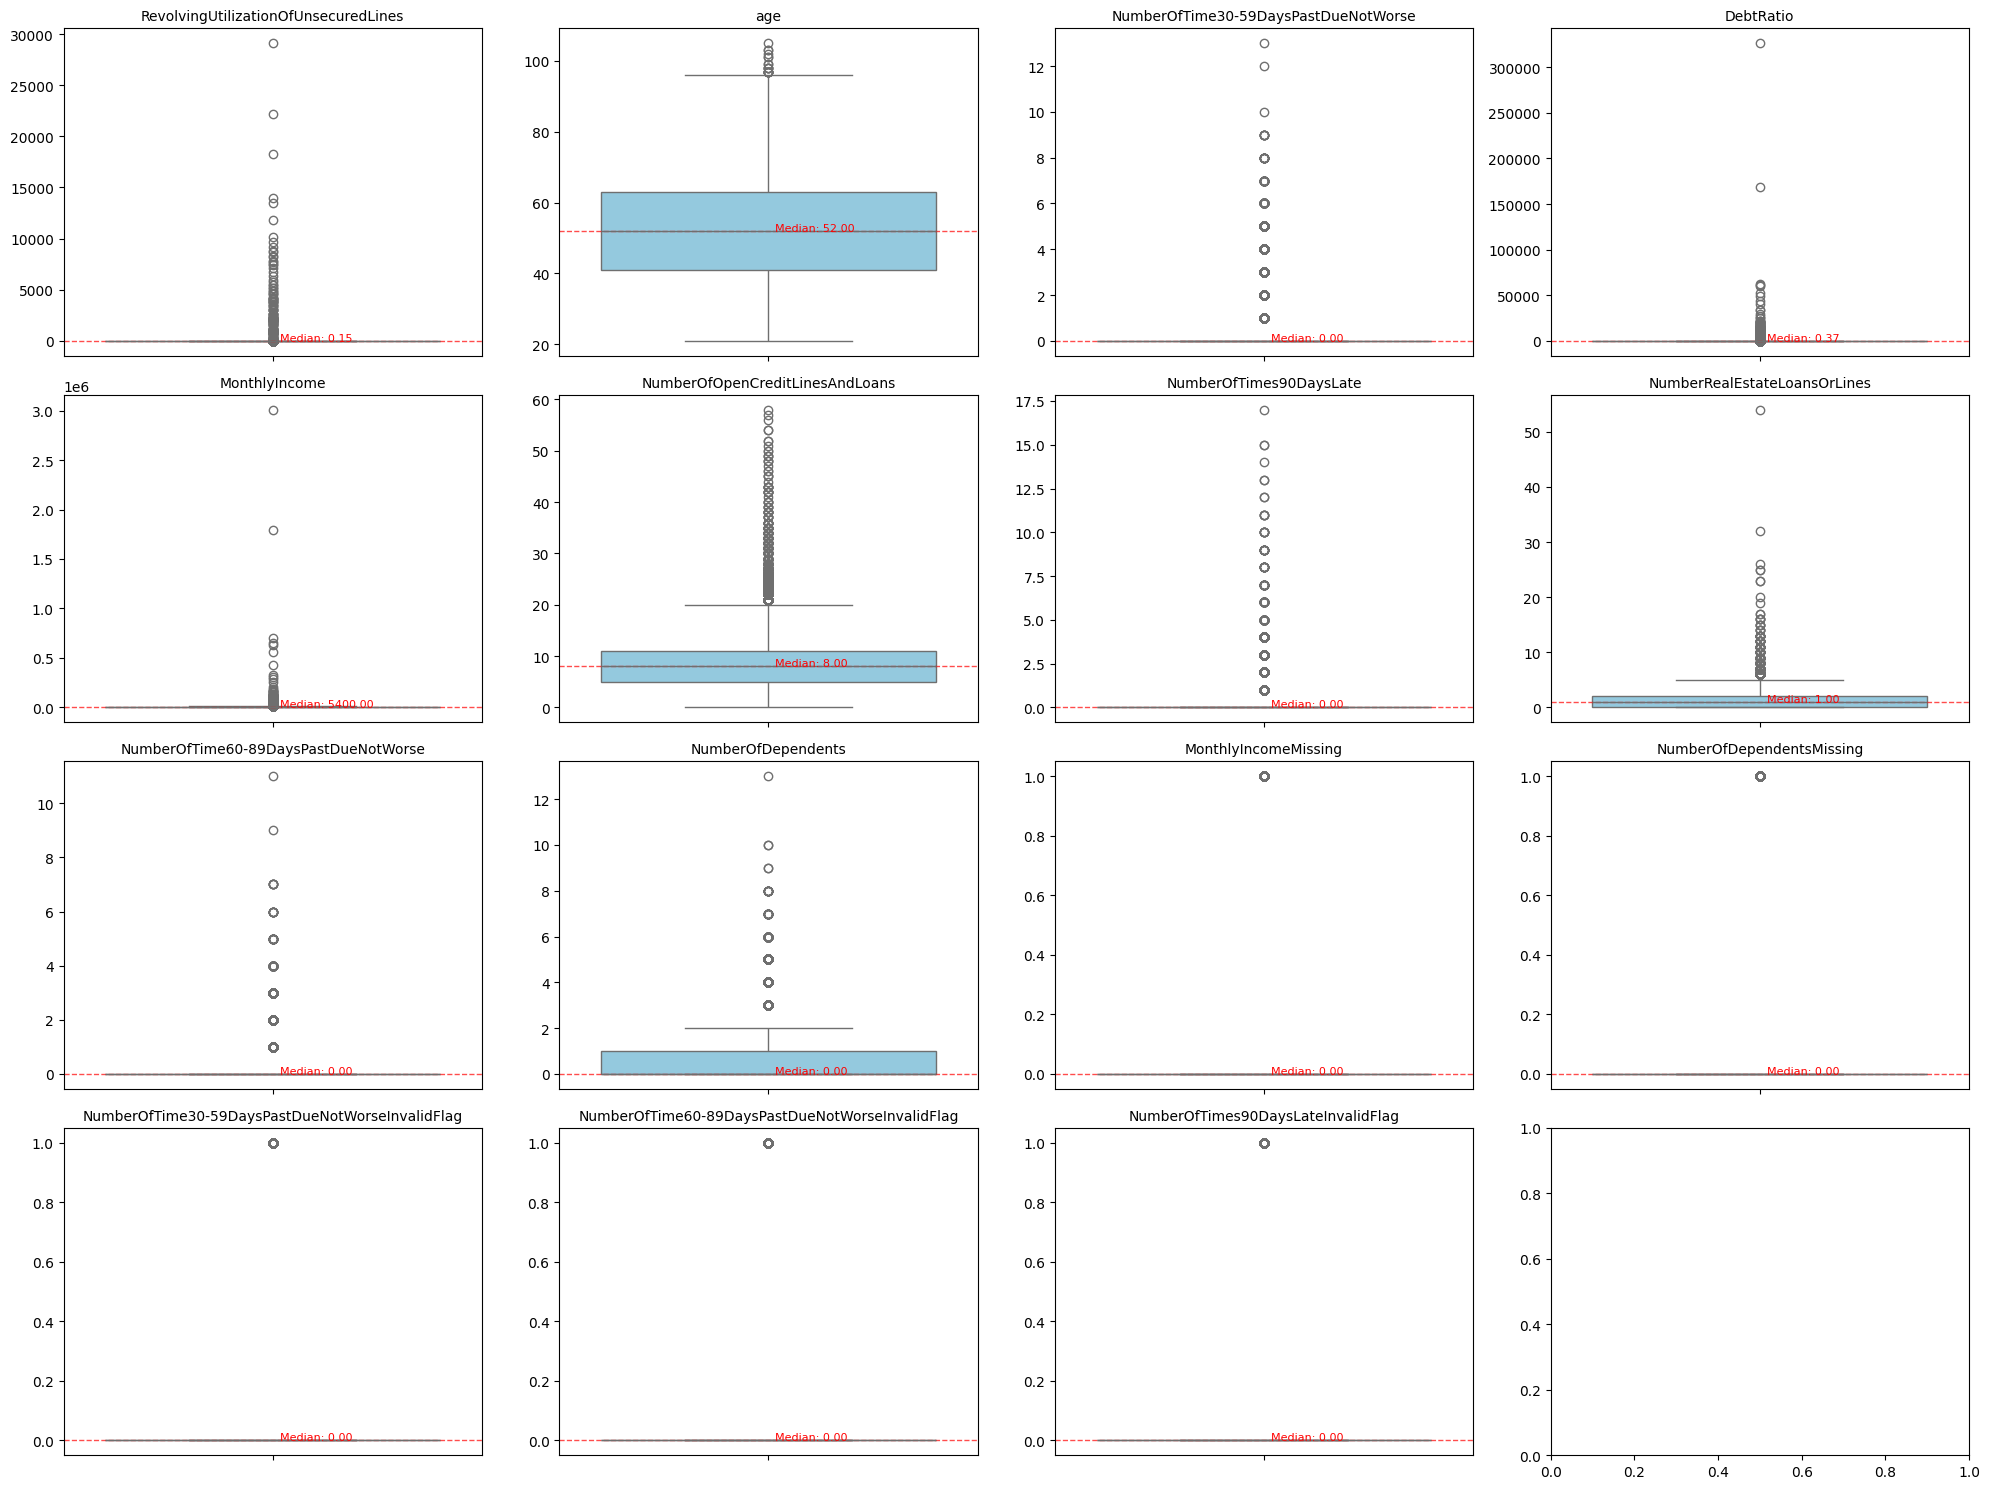

In [19]:
fig, axes = plt.subplots(4, 4, figsize=(20, 15))
axes = axes.flatten()

for i, col in enumerate(X_train_processed.columns):
    sns.boxplot(y=X_train_processed[col], ax=axes[i], color='skyblue')
    axes[i].set_title(f'{col}', fontsize=10)
    axes[i].set_ylabel('')
    
    median_val = X_train_processed[col].median()
    axes[i].axhline(median_val, color='red', linestyle='--', linewidth=1, alpha=0.7)
    axes[i].text(0.5, median_val, f'  Median: {median_val:.2f}', 
                 transform=axes[i].get_yaxis_transform(), 
                 fontsize=8, color='red')

plt.tight_layout()
plt.show()

In [20]:
X_train_final = add_features(X_train_processed)
X_test_final = add_features(X_test_processed)

assert X_train_final.equals(preprocessor.transform(X_train))
assert X_test_final.equals(preprocessor.transform(X_test))

In [21]:
X_train_final.head()

,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,MonthlyIncomeMissing,NumberOfDependentsMissing,NumberOfTime30-59DaysPastDueNotWorseInvalidFlag,NumberOfTime60-89DaysPastDueNotWorseInvalidFlag,NumberOfTimes90DaysLateInvalidFlag,TotalMonthlyDebt,IncomePerDependentAdjusted,TotalDelinquencies,RealEstateToTotalCredit
75797,0.174595,54.0,0.0,0.360189,4666.0,14,0.0,1,0.0,0.0,0,0,0,0,0,1680.639812,4666.0,0.0,0.066667
36814,0.254972,29.0,2.0,0.013997,5000.0,4,0.0,0,0.0,0.0,0,0,0,0,0,69.986005,5000.0,2.0,0.000000
83600,0.279406,50.0,1.0,0.301446,3041.0,10,0.0,0,0.0,0.0,0,0,0,0,0,916.698554,3041.0,1.0,0.000000
26147,0.028794,80.0,0.0,0.276862,2000.0,4,0.0,1,0.0,0.0,0,0,0,0,0,553.723138,2000.0,0.0,0.200000
72802,0.506475,44.0,0.0,0.330316,6959.0,6,0.0,1,0.0,1.0,0,0,0,0,0,2298.669684,3479.5,0.0,0.142857


In [22]:
X_test_final.head()

,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,MonthlyIncomeMissing,NumberOfDependentsMissing,NumberOfTime30-59DaysPastDueNotWorseInvalidFlag,NumberOfTime60-89DaysPastDueNotWorseInvalidFlag,NumberOfTimes90DaysLateInvalidFlag,TotalMonthlyDebt,IncomePerDependentAdjusted,TotalDelinquencies,RealEstateToTotalCredit
48928,0.769287,51.0,1.0,0.359543,7083.0,11,0.0,2,1.0,0.0,0,0,0,0,0,2.546640e+03,7083.0,2.0,0.166667
63095,0.000000,78.0,0.0,0.000000,5400.0,2,0.0,0,0.0,0.0,1,1,0,0,0,0.000000e+00,5400.0,0.0,0.000000
63310,0.391326,37.0,0.0,1032.000000,5400.0,16,0.0,0,0.0,0.0,1,0,0,0,0,5.572800e+06,5400.0,0.0,0.000000
10090,0.039731,74.0,0.0,797.000000,5400.0,2,0.0,1,0.0,0.0,1,0,0,0,0,4.303800e+06,5400.0,0.0,0.333333
65729,0.586359,38.0,0.0,0.301635,1650.0,6,0.0,0,0.0,1.0,0,0,0,0,0,4.976984e+02,825.0,0.0,0.000000


TotalDelinquencies                                 0.385921
NumberOfTimes90DaysLate                            0.308826
NumberOfTime30-59DaysPastDueNotWorse               0.268487
NumberOfTime60-89DaysPastDueNotWorse               0.263517
NumberOfTimes90DaysLateInvalidFlag                 0.083720
NumberOfTime60-89DaysPastDueNotWorseInvalidFlag    0.083720
NumberOfTime30-59DaysPastDueNotWorseInvalidFlag    0.083720
NumberOfDependents                                 0.043778
RevolvingUtilizationOfUnsecuredLines              -0.000634
TotalMonthlyDebt                                  -0.008196
DebtRatio                                         -0.008587
NumberRealEstateLoansOrLines                      -0.008715
NumberOfDependentsMissing                         -0.016094
MonthlyIncome                                     -0.017823
RealEstateToTotalCredit                           -0.017900
MonthlyIncomeMissing                              -0.017904
IncomePerDependentAdjusted              

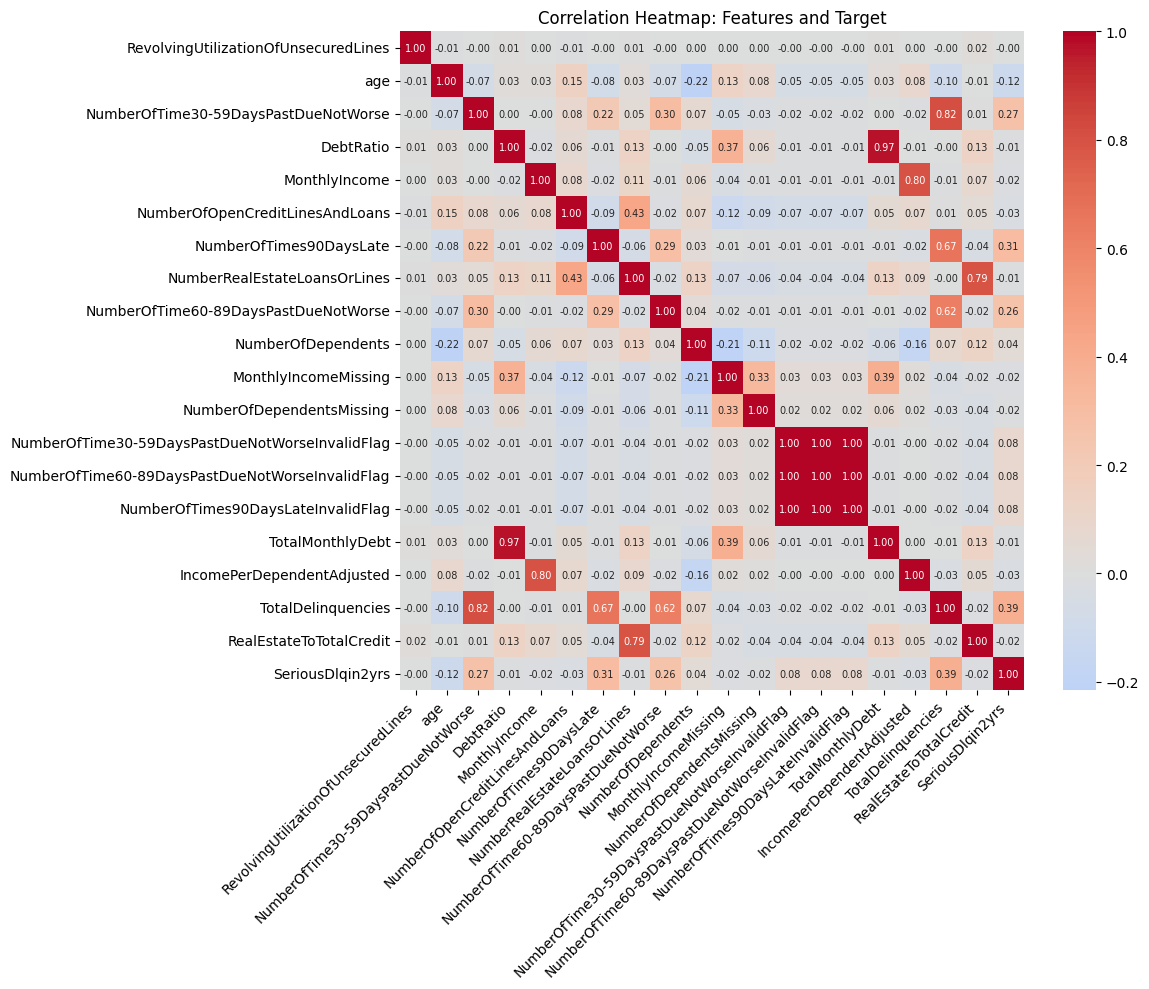

In [23]:

train_corr_df = X_train_final.copy()

train_corr_df["SeriousDlqin2yrs"] = y_train_raw

corr_mat = train_corr_df.corr(numeric_only=True)

target_corr = (
    corr_mat["SeriousDlqin2yrs"]
    .drop("SeriousDlqin2yrs")
    .sort_values(ascending=False)
)

print(target_corr)

plt.figure(figsize=(12, 10))

sns.heatmap(
    corr_mat,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7}
)

plt.title("Correlation Heatmap: Features and Target")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [24]:
X_train_final.isnull().sum()

RevolvingUtilizationOfUnsecuredLines               0
age                                                0
NumberOfTime30-59DaysPastDueNotWorse               0
DebtRatio                                          0
MonthlyIncome                                      0
NumberOfOpenCreditLinesAndLoans                    0
NumberOfTimes90DaysLate                            0
NumberRealEstateLoansOrLines                       0
NumberOfTime60-89DaysPastDueNotWorse               0
NumberOfDependents                                 0
MonthlyIncomeMissing                               0
NumberOfDependentsMissing                          0
NumberOfTime30-59DaysPastDueNotWorseInvalidFlag    0
NumberOfTime60-89DaysPastDueNotWorseInvalidFlag    0
NumberOfTimes90DaysLateInvalidFlag                 0
TotalMonthlyDebt                                   0
IncomePerDependentAdjusted                         0
TotalDelinquencies                                 0
RealEstateToTotalCredit                       

In [25]:
X_train_final.to_csv(DATA_DIR / "X_train_final.csv", index=False)
X_test_final.to_csv(DATA_DIR / "X_test_final.csv", index=False)

y_train_raw.to_csv(DATA_DIR / "y_train_raw.csv", index=False)
y_test_raw.to_csv(DATA_DIR / "y_test_raw.csv", index=False)

preprocessor.save(MODELS_DIR / "preprocessor.json")